In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


In [2]:
df = pd.read_csv('/content/ABC Company.xlsx - Sheet1.csv')
df.head(10)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,5000000.0
5,Amir Johnson,Boston Celtics,90,PF,29,06-Sep,240,NaN,12000000.0
6,Jordan Mickey,Boston Celtics,55,PF,21,06-Aug,235,LSU,1170960.0
7,Kelly Olynyk,Boston Celtics,41,C,25,7-0,238,Gonzaga,2165160.0
8,Terry Rozier,Boston Celtics,12,PG,22,06-Feb,190,Louisville,1824360.0
9,Marcus Smart,Boston Celtics,36,PG,22,06-Apr,220,Oklahoma State,3431040.0


In [3]:
df.shape[0]
df.shape[1]
df.columns
df.info
df.isnull().sum()



,0
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


Pre Processing

In [4]:
np.random.seed(42)
df["Height"] = np.random.randint(150,181,size=len(df))
#to verify the uploaded values

print(df["Height"].head(10))
print("minimum height:",df["Height"].min())
print("maximum height:",df["Height"].max())

0    156
1    169
2    178
3    164
4    160
5    157
6    178
7    170
8    156
9    175
Name: Height, dtype: int64
minimum height: 150
maximum height: 180


## ANALYSIS TASK


1.Distribution of employees across teams

In [7]:


team_count = df["Team"].value_counts()
team_percentage = (df["Team"].value_counts(normalize=True)*100)
team_analysis = pd.DataFrame({"Employee count":team_count, "Percentage":team_percentage.round(2)})
print(team_analysis)

                        Employee count  Percentage
Team                                              
New Orleans Pelicans                19        4.15
Memphis Grizzlies                   18        3.93
Utah Jazz                           16        3.49
Milwaukee Bucks                     16        3.49
New York Knicks                     16        3.49
Boston Celtics                      15        3.28
Los Angeles Clippers                15        3.28
Los Angeles Lakers                  15        3.28
Phoenix Suns                        15        3.28
Sacramento Kings                    15        3.28
Brooklyn Nets                       15        3.28
Philadelphia 76ers                  15        3.28
Toronto Raptors                     15        3.28
Golden State Warriors               15        3.28
Indiana Pacers                      15        3.28
Detroit Pistons                     15        3.28
Cleveland Cavaliers                 15        3.28
Chicago Bulls                  

Visualisation of Distribution of employees across teams


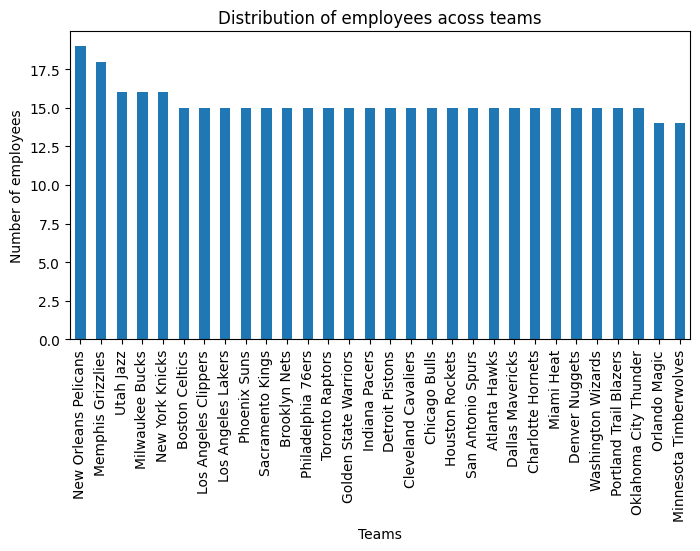

In [8]:
plt.figure(figsize=(8,4))
team_count.plot(kind="bar")
plt.title("Distribution of employees acoss teams")
plt.xlabel("Teams")
plt.ylabel("Number of employees")
plt.xticks(rotation=90)
plt.show()

2.Segregate employees by position

In [9]:
position_count = df["Position"].value_counts()
print(position_count)

Position
SG    102
PF    100
PG     92
SF     85
C      79
Name: count, dtype: int64


visualisation of sgregate employees by position

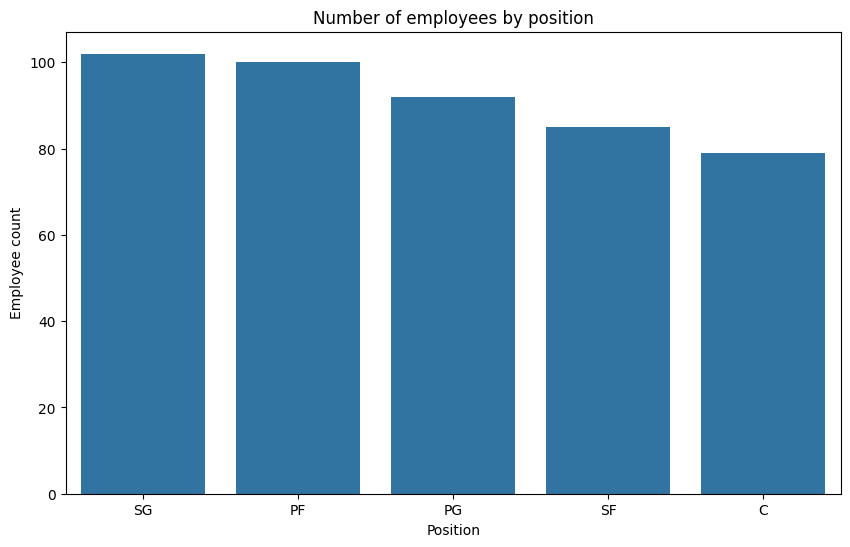

In [10]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x="Position",order=position_count.index)
plt.title("Number of employees by position")
plt.xlabel("Position")
plt.ylabel("Employee count")
plt.show()

3. Identify the predominant age group

In [12]:
bins =[0,20,25,30,35,40,45,100]

labels = ["Under 20","20-24","25-29","30-34","35-39","40-44","45+"]

df["Age Group"] = pd.cut(df["Age"],bins=bins,labels=labels,right=False)

age_group_count = df["Age Group"].value_counts().sort_index()

print(age_group_count)
print("Predominant Age Group:",age_group_count.idxmax())

Age Group
Under 20      2
20-24       152
25-29       182
30-34        90
35-39        29
40-44         3
45+           0
Name: count, dtype: int64
Predominant Age Group: 25-29


Visualisation of Predominant age group

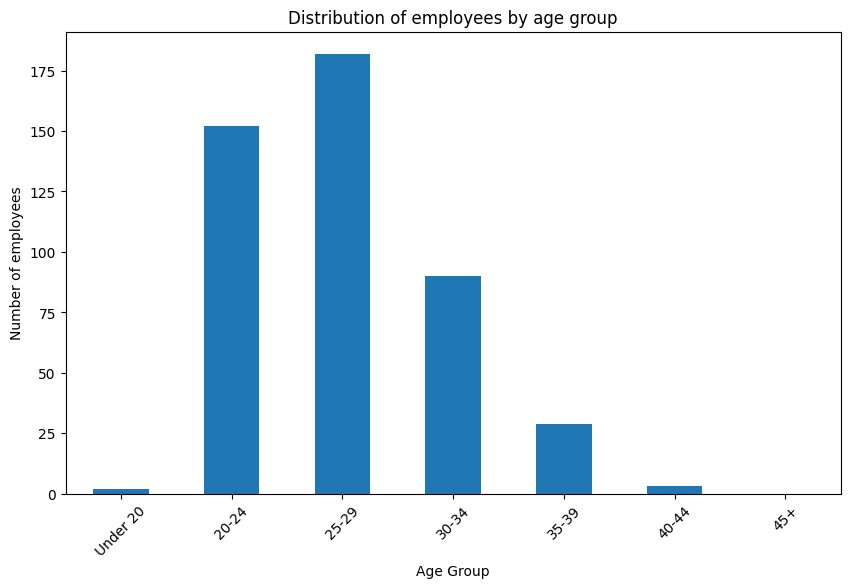

In [13]:
plt.figure(figsize=(10,6))
age_group_count.plot(kind="bar")
plt.title("Distribution of employees by age group")
plt.xlabel("Age Group")
plt.ylabel("Number of employees")
plt.xticks(rotation=45)
plt.show()

4. Salary expenditure by team

In [17]:
df["Salary"] = pd.to_numeric(df["Salary"],errors="coerce")

# calculate the total salary expenditure by team.

team_salary = df.groupby("Team")["Salary"].sum().sort_values(ascending=False)
print("Salary expenditure by team:")
print(team_salary)
print("\nTeam with highest salary:")
print(team_salary.idxmax)

Salary expenditure by team:
Team
Cleveland Cavaliers       106988689.0
Los Angeles Clippers       94854640.0
Oklahoma City Thunder      93765298.0
Golden State Warriors      88868997.0
Chicago Bulls              86783378.0
San Antonio Spurs          84442733.0
New Orleans Pelicans       82750774.0
Miami Heat                 82515673.0
Charlotte Hornets          78340920.0
Memphis Grizzlies          76550880.0
Washington Wizards         76328636.0
Houston Rockets            75283021.0
New York Knicks            73303898.0
Atlanta Hawks              72902950.0
Los Angeles Lakers         71770431.0
Sacramento Kings           71683666.0
Dallas Mavericks           71198732.0
Toronto Raptors            71117611.0
Milwaukee Bucks            69603517.0
Detroit Pistons            67168263.0
Indiana Pacers             66751826.0
Utah Jazz                  64007367.0
Phoenix Suns               63445135.0
Orlando Magic              60161470.0
Denver Nuggets             60121930.0
Minnesota Timberw

Visualisation of salary expenditure by team

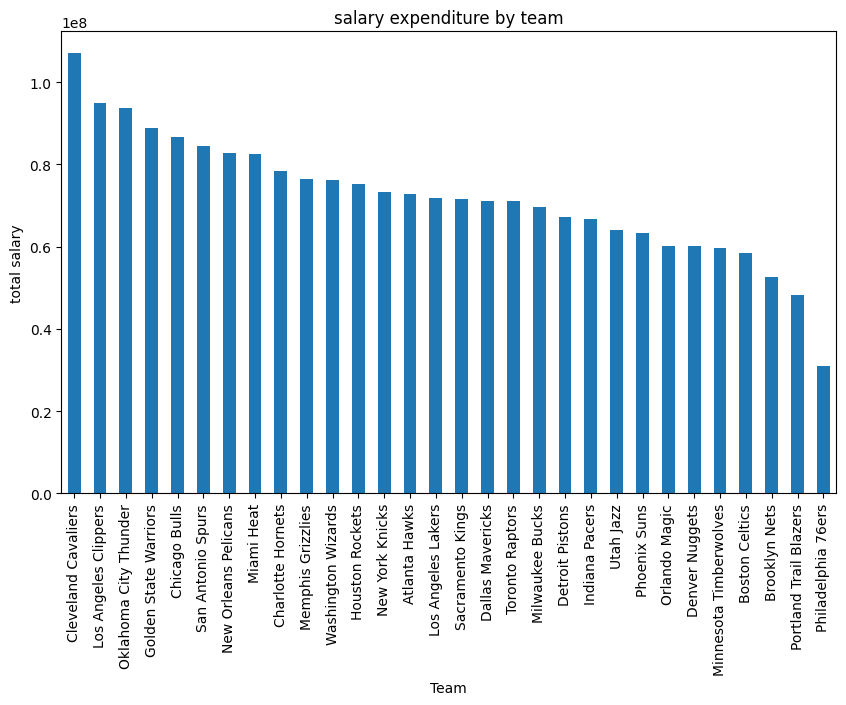

In [16]:
plt.figure(figsize=(10,6))
team_salary.plot(kind="bar")
plt.title("salary expenditure by team")
plt.xlabel("Team")
plt.ylabel("total salary")
plt.xticks(rotation=90)
plt.show()

5. Salary expenditure byposition

In [18]:
position_salary =df.groupby("Position")["Salary"].sum().sort_values(ascending=False)
print("Salary expenditure by position:")
print(position_salary)
print("\n Position with highest salary expenditure:")
print(position_salary.idxmax)


Salary expenditure by position:
Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64

 Position with highest salary expenditure:
<bound method Series.idxmax of Position
C     466377332.0
PG    446848971.0
PF    442560850.0
SF    408020976.0
SG    396976258.0
Name: Salary, dtype: float64>


Visualisation of salary expenditure by position

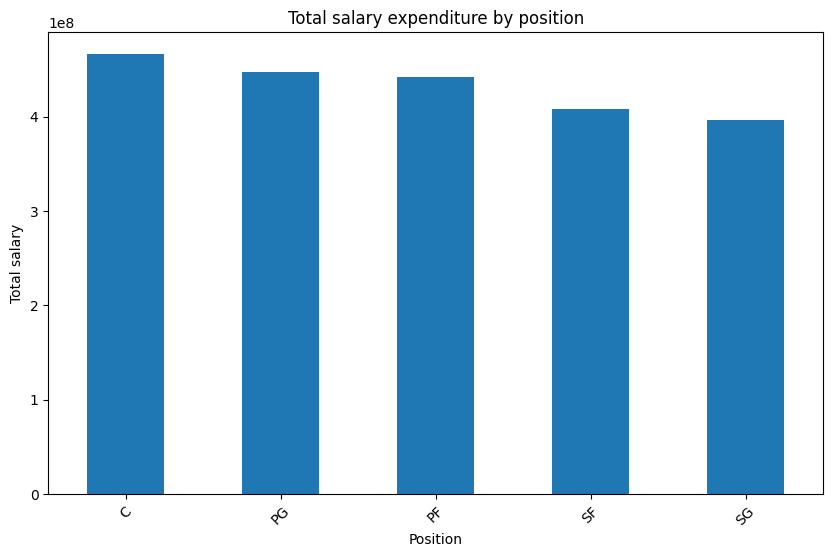

In [21]:
plt.figure(figsize=(10,6))
position_salary.plot(kind="bar")
plt.title("Total salary expenditure by position")
plt.xlabel("Position")
plt.ylabel("Total salary")
plt.xticks(rotation=45)
plt.show()

6. Investigate the correlation between age and salary

In [37]:
correlation = df[["Age", "Salary"]].corr()
print("Correlation between age and salary :",correlation)

Correlation between age and salary :              Age    Salary
Age     1.000000  0.214009
Salary  0.214009  1.000000


Visualisation of correlation between age and salary

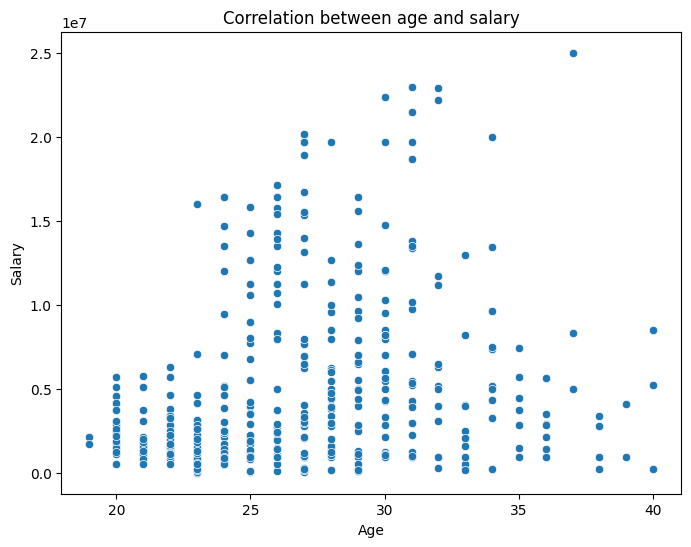

In [38]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df,x="Age",y="Salary")
plt.title("Correlation between age and salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

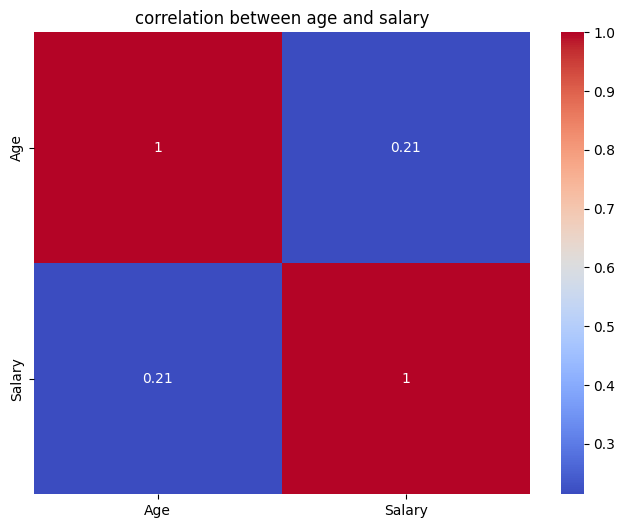

In [39]:
plt.figure(figsize=(8,6))
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("correlation between age and salary")
plt.show()

***DATA STORY***

The analysis of the ABC company emplyee dataset was conducted to understand the distribution of employees,their positions,age groups,salary expenditure and the relationship between age and salary.

***1.Team distribution***

The team with highest number of employees is New Orleans Pelicans accounting for around 4.15 % of the total workers. This helps to identify how employees are distributed across team.

***2.position distribution***

The most common position is SG with 102 number of employees.This reveals which position is most represented in the organisation.

***3.Age distribution***

The predominant age group in the company is 25-29.total of 182 employees is under this age group. Which denotes most of the employees in the company are still young.

***4.Salary expenditure***

The team with highest salary expenditure is Cleveland Caveliers while 'C' has the highest expenditure among positions. This finding helps to compare the salary allocation across oraganisational teams.

***5.Age and salary relationship***

The correlation matrix shows age and salary is weakly correlated.

***conclusion***

The project demonstrates how Python, Pandas, Matplotlib, and Seaborn can be used to clean, analyze, and visualize employee data. The results provide insights into workforce composition and recorded salary expenditure.